# Read me

Este notebook usa DBSCAN para agrupar músicas a partir das features de áudio do Spotify e recomendar faixas próximas ao perfil das músicas de entrada.

**Objetivo:** identificar padrões sonoros que atravessem gêneros musicais.

**Abordagens**
- **Baseline:** DBSCAN nas 8 features escaladas, sem redução de dimensionalidade.
- **PCA:** DBSCAN nos primeiros 3, 4 e 5 componentes principais, número sugerido no notebook do Victor a partir da variância explicada.

**Critérios de sucesso do MVP**
- **Similaridade sonora:** avaliar se os clusters são coerentes (silhouette sem ruído, % de ruído e tamanho dos clusters).
- **Diversidade de gêneros:** verificar se os clusters misturam gêneros em vez de reproduzi-los (gênero dominante e entropia de gêneros).

**Particularidades do DBSCAN**
- Como o DBSCAN é mais pesado, a busca de parâmetros usa uma amostra de 10 mil músicas (a mesma para todos os modelos).
- O DBSCAN não tem `predict`. Por isso, o modelo final é treinado na amostra e as demais músicas (e o perfil de entrada do recomendador) são atribuídas ao cluster do core point mais próximo, desde que ele esteja dentro de `eps`. Fora disso, a música é ruído (-1).

In [18]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

from IPython.display import display

import joblib


# Adiciona a pasta raiz do projeto ao caminho de busca (a pasta app fica fora da pasta notebooks)
sys.path.append("..")


from app.preprocessing.preprocessing import preprocessing


import app.spotify.spotify as spo


os.environ["LOKY_MAX_CPU_COUNT"] = "8"

In [19]:
input_size = 5
output_size = 10


token = spo.get_access_token()

# Load data

In [20]:
# Carrega dados de músicas do Spotify
df = pd.read_csv("../raw_data/spotify-tracks-dataset-detailed.csv")
df.head()

,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [21]:
print(f'Loaded {len(df)} rows')

Loaded 114000 rows


# Pre-process data

A função `preprocessing` reúne todas as etapas de preparação da base em um único lugar, para que o mesmo tratamento possa ser reaplicado de forma idêntica. As etapas, nesta ordem, são:

1. Remove o gênero comedy
2. Seleciona as colunas necessárias
3. Remove valores nulos
4. Remove duplicatas exatas
5. Preserva todos os gêneros de cada música (uma música pode aparecer em mais de um gênero) e mantém uma linha por música
6. Separa metadados e features
7. Escalona as features

**Scaling:** foi adotado o StandardScaler, que padroniza os valores para média 0 e desvio padrão 1. Como o DBSCAN é baseado em distância, features em escalas muito diferentes (como loudness e tempo, em relação às variáveis entre 0 e 1) dominariam o cálculo se não fossem padronizadas.

**Split Train Val Test:** não há divisão, porque a clusterização não é supervisionada. O scaler foi ajustado na base completa.

### Aplicação do Pre Processing

In [22]:
# Aplica o pre processing na base
X_scaled, df_metadata, scaler, features = preprocessing(df)


audio_features = features

### Conferência dos Dados

Formato da matriz de features escaladas, metadados das músicas e a união dos dois.

In [23]:
# Verifica o formato da matriz de features escaladas
X_scaled.shape

(80175, 8)

In [24]:
# Verifica os metadados das músicas
df_metadata.head()

,track_id,artists,track_name,genres
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,"[acoustic, j-pop, singer-songwriter, songwriter]"
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost - Acoustic,"[acoustic, chill]"
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,[acoustic]
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Can't Help Falling In Love,[acoustic]
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,[acoustic]


In [25]:
# Cria o dataframe com as features escaladas
df_scaled = pd.DataFrame(X_scaled, columns=features)
df_scaled.head()

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,valence,tempo
0,0.676937,-0.701560,0.323475,0.776805,-0.854487,-0.551196,0.960811,-1.182342
1,-0.815682,-1.857298,-1.792992,-0.041318,1.801679,-0.551182,-0.762295,-1.535282
2,-0.710732,-1.101171,-0.279443,-0.293991,-0.324922,-0.551199,-1.327690,-1.574441
3,-1.713586,-2.274147,-2.051270,-0.531946,1.745089,-0.550983,-1.239227,1.993142
4,0.338766,-0.772080,-0.268748,-0.332015,0.446492,-0.551199,-1.146917,-0.098203


In [26]:
# Une os metadados com as features escaladas
df_final = pd.concat([df_metadata, df_scaled], axis=1)
df_final.head()

,track_id,artists,track_name,genres,danceability,energy,loudness,speechiness,acousticness,instrumentalness,valence,tempo
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,"[acoustic, j-pop, singer-songwriter, songwriter]",0.676937,-0.701560,0.323475,0.776805,-0.854487,-0.551196,0.960811,-1.182342
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost - Acoustic,"[acoustic, chill]",-0.815682,-1.857298,-1.792992,-0.041318,1.801679,-0.551182,-0.762295,-1.535282
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,[acoustic],-0.710732,-1.101171,-0.279443,-0.293991,-0.324922,-0.551199,-1.327690,-1.574441
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Can't Help Falling In Love,[acoustic],-1.713586,-2.274147,-2.051270,-0.531946,1.745089,-0.550983,-1.239227,1.993142
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,[acoustic],0.338766,-0.772080,-0.268748,-0.332015,0.446492,-0.551199,-1.146917,-0.098203


#### Observações sobre as features

- Energy, loudness e acousticness são fortemente correlacionadas e pesam como um único eixo de "intensidade" na distância dos algoritmos.
- Speechiness, instrumentalness e acousticness têm distribuição muito assimétrica, e loudness e duration têm outliers. Isso afeta o `StandardScaler`.

# Model selection

Nesta seção, comparamos o baseline com os espaços reduzidos pelo PCA para escolher o modelo final. As análises servem apenas à seleção; o modelo usado pelo recomendador é treinado novamente na seção **Train**.

## Funções Auxiliares de Avaliação

Os modelos são comparados pelas mesmas métricas:

- **Silhouette** (maior = melhor): calculado só nos pontos que não são ruído. O silhouette sozinho engana no DBSCAN: um resultado com 1 cluster gigante mais um minúsculo e quase nenhum ruído pode ter silhouette alto e ser inútil para o recomendador. Por isso, acompanhamos também `ruido_pct` e `maior_cluster_pct`.
- **silhouette_8d:** o silhouette dos mesmos clusters medido no espaço das 8 features originais, para comparar baseline e PCA no mesmo referencial (o silhouette de cada modelo é medido no espaço em que ele foi treinado, com 8, 3, 4 ou 5 dimensões).
- **Diversidade de gêneros:** considera o gênero dominante (menor = mais misturado) e a entropia de gêneros (maior = mais diverso). O tamanho dos clusters também é analisado para evitar conclusões isoladas.

In [27]:
# Cria uma linha por par música-gênero
genres_exp = df_metadata["genres"].explode().rename("genre")


# Conta a quantidade de gêneros distintos (usada para normalizar a entropia)
N_GENEROS = genres_exp.nunique()


def metricas_genero(labels):
    """Mede o quanto os clusters misturam gêneros (ligado ao critério de diversidade de gêneros do MVP).

    labels: pd.Series com o cluster de cada música (índice = índice de df_metadata). Ruído deve ser removido antes.
    - genero_dominante_pct: share do gênero mais comum em cada cluster, ponderado pelo tamanho do cluster (menor = mais misturado)
    - entropia_generos: entropia normalizada (0 a 1) da distribuição de gêneros em cada cluster, ponderada pelo tamanho (maior = mais diverso)
    """
    # Cruza os gêneros de cada música com o seu cluster
    g = genres_exp.to_frame().join(labels.rename("cluster"), how="inner")

    # Conta a quantidade de músicas por cluster e gênero
    tab = g.groupby(["cluster", "genre"]).size().unstack(fill_value=0)

    # Calcula a distribuição de gêneros dentro de cada cluster e o peso (tamanho) de cada cluster
    p = tab.div(tab.sum(axis=1), axis=0)
    peso = tab.sum(axis=1) / tab.values.sum()

    # Calcula o gênero dominante e a entropia, ponderados pelo tamanho do cluster
    dominante = (p.max(axis=1) * peso).sum() * 100
    entropia = (-(p * np.log(p.where(p > 0, 1))).sum(axis=1) / np.log(N_GENEROS) * peso).sum()
    return {"genero_dominante_pct": dominante, "entropia_generos": entropia}



def perfil_clusters(labels, top_n=3):
    """Média das 8 features (escaladas) por cluster, tamanho do cluster e gêneros mais comuns. Ignora ruído (-1)."""
    # Remove o ruído (-1) e nomeia a série de clusters
    labels = labels[labels != -1].rename("cluster")

    # Calcula a média de cada feature escalada por cluster
    medias = df_scaled.loc[labels.index].groupby(labels).mean()

    # Identifica os gêneros mais comuns de cada cluster
    g = genres_exp.to_frame().join(labels, how="inner")
    top = g.groupby("cluster")["genre"].agg(lambda s: ", ".join(s.value_counts().head(top_n).index))

    # Monta o perfil com o percentual de músicas e os gêneros mais comuns
    perfil = medias.copy()
    perfil["pct_musicas"] = labels.value_counts(normalize=True).sort_index() * 100
    perfil["top_generos"] = top
    return perfil


def plot_perfil(perfil, titulo, ax):
    """Heatmap com a média de cada feature (em desvios-padrão) por cluster."""
    medias = perfil[features]
    im = ax.imshow(medias.values, cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
    ax.set_xticks(range(len(features)))
    ax.set_xticklabels(features, rotation=45, ha="right")
    ax.set_yticks(range(len(medias)))
    ax.set_yticklabels([f"c{c} ({p:.0f}%)" for c, p in zip(medias.index, perfil["pct_musicas"])])
    ax.set_title(titulo)
    return im



def plot_pc12(idx, labels, titulo, ax):
    """Dispersão em PC1 x PC2. idx = posições das músicas plotadas; labels = cluster de cada uma (ruído = -1 em cinza)."""
    labels = np.asarray(labels)
    ruido = labels == -1
    ax.scatter(pcs_2d[idx[ruido], 0], pcs_2d[idx[ruido], 1], c="lightgrey", s=3, alpha=0.4)
    ax.scatter(pcs_2d[idx[~ruido], 0], pcs_2d[idx[~ruido], 1], c=labels[~ruido], cmap="tab10", s=4, alpha=0.6)
    ax.set_title(titulo)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")

## Espaços do Modelo

### Baseline

O DBSCAN nas 8 features já escaladas (`X_scaled`), sem redução de dimensionalidade, é usado como modelo de referência.

### Improve the Baseline - PCA

O PCA é usado para avaliar se a redução de dimensionalidade melhora o agrupamento. Com 8 componentes o PCA é só uma rotação dos dados, que preserva as distâncias: rodar o modelo nos 8 PCs daria o mesmo resultado do baseline. Por isso, a comparação considera apenas espaços com menos componentes.

### Variância Explicada e Loadings

A variância explicada e os loadings ajudam a entender quanta informação é preservada e quais features contribuem para cada componente. É o mesmo PCA do Victor (8 componentes).

In [28]:
# Ajusta o PCA com todos os componentes (mesmo PCA do Victor, 8 componentes)
pca_full = PCA().fit(X_scaled)


# Calcula a variância explicada e acumulada por componente
variancia = pd.DataFrame({
    "PC": [f"PC{i}" for i in range(1, len(features) + 1)],
    "variancia_explicada": pca_full.explained_variance_ratio_,
    "variancia_acumulada": np.cumsum(pca_full.explained_variance_ratio_),
})
display(variancia.round(4))


# Calcula o peso de cada feature nos 5 primeiros componentes
loadings = pd.DataFrame(
    pca_full.components_.T,
    index=features,
    columns=[f"PC{i}" for i in range(1, len(features) + 1)]
)

loadings.iloc[:, :5].round(2)

,PC,variancia_explicada,variancia_acumulada
0,PC1,0.3580,0.3580
1,PC2,0.1771,0.5351
2,PC3,0.1217,0.6568
3,PC4,0.1145,0.7713
4,PC5,0.1089,0.8801
5,PC6,0.0630,0.9432
6,PC7,0.0404,0.9835
7,PC8,0.0165,1.0000


,PC1,PC2,PC3,PC4,PC5
danceability,0.23,0.56,0.20,-0.33,0.31
energy,0.52,-0.25,-0.03,-0.17,-0.02
loudness,0.52,-0.09,-0.17,-0.01,-0.20
speechiness,0.16,0.05,0.91,0.20,-0.30
acousticness,-0.45,0.32,-0.01,0.33,-0.02
instrumentalness,-0.26,-0.34,0.31,-0.53,0.51
valence,0.28,0.56,-0.09,0.07,0.33
tempo,0.20,-0.30,0.07,0.65,0.63


#### Variância Explicada

Seguindo o gráfico de variância explicada do PCA, optei por testar **3, 4 e 5 componentes**.

### Definição dos Espaços

Define os espaços usados na comparação: baseline e versões reduzidas pelo PCA.

In [29]:
NOME_BASELINE = "Baseline (8 features)"
espacos = {NOME_BASELINE: X_scaled}


# Define a quantidade de componentes testados
N_COMPONENTES = [3, 4, 5]


# Cria os espaços reduzidos do PCA e adiciona aos espaços do modelo
X_pca = pca_full.transform(X_scaled)
for n in N_COMPONENTES:
    espacos[f"PCA {n}"] = np.ascontiguousarray(X_pca[:, :n])


# Verifica o formato de cada espaço (baseline e PCA com 3, 4 e 5 componentes)
for nome, M in espacos.items():
    print(nome, M.shape)

Baseline (8 features) (80175, 8)
PCA 3 (80175, 3)
PCA 4 (80175, 4)
PCA 5 (80175, 5)


## Amostra

A amostra de 10 mil músicas é sorteada uma única vez, então baseline e PCA são comparados nas mesmas músicas.

In [30]:
# Define o tamanho da amostra usada na busca de parâmetros
N_AMOSTRA = 10000


# Sorteia a amostra uma única vez (mesma amostra para todos os modelos)
idx_amostra = df_scaled.sample(n=N_AMOSTRA, random_state=42).index
pos_amostra = idx_amostra.to_numpy()


# Seleciona as músicas da amostra em cada espaço
espacos_amostra = {nome: M[pos_amostra] for nome, M in espacos.items()}


# Define o espaço de referência (8 features) usado no silhouette_8d
X_amostra_base = espacos_amostra[NOME_BASELINE]


# Verifica o formato de cada espaço na amostra
print({nome: M.shape for nome, M in espacos_amostra.items()})

{'Baseline (8 features)': (10000, 8), 'PCA 3': (10000, 3), 'PCA 4': (10000, 4), 'PCA 5': (10000, 5)}


## K-Distance Plot (um por espaço)

O `eps` do DBSCAN depende do espaço: ao reduzir de 8 para 3-5 dimensões as distâncias encolhem, então **o `eps` do baseline não pode ser reaproveitado no PCA**. Por isso o K-Distance Plot é refeito para cada espaço e para alguns valores de `min_samples`.

Em vez de um grid fixo de `eps` (0,5; 0,7; ...), optei por escolher o `eps` por **quantis da própria curva de k-distância**. Um ponto é *core* quando o seu k-ésimo vizinho está dentro de `eps`, então `eps` no quantil 0,90 faz cerca de 90% dos pontos serem core. Isso deixa a busca equivalente entre os espaços.

In [31]:
# Define os valores de min_samples testados
MIN_SAMPLES = [5, 10, 20]


# Define os quantis da curva de k-distância usados para escolher o eps
QUANTIS_EPS = [0.60, 0.70, 0.80, 0.90, 0.95, 0.99]


def k_distancias(Xs, min_samples):
    """Distância de cada ponto ao seu min_samples-ésimo vizinho (o próprio ponto conta, como no DBSCAN), ordenada."""
    # Encontra os vizinhos mais próximos de cada ponto
    nn = NearestNeighbors(n_neighbors=min_samples).fit(Xs)
    dist, _ = nn.kneighbors(Xs)

    # Ordena a distância ao k-ésimo vizinho
    return np.sort(dist[:, -1])



# Calcula a k-distância de cada espaço para cada valor de min_samples
kdists = {
    (nome, ms): k_distancias(Xs, ms)
    for nome, Xs in espacos_amostra.items()
    for ms in MIN_SAMPLES
}

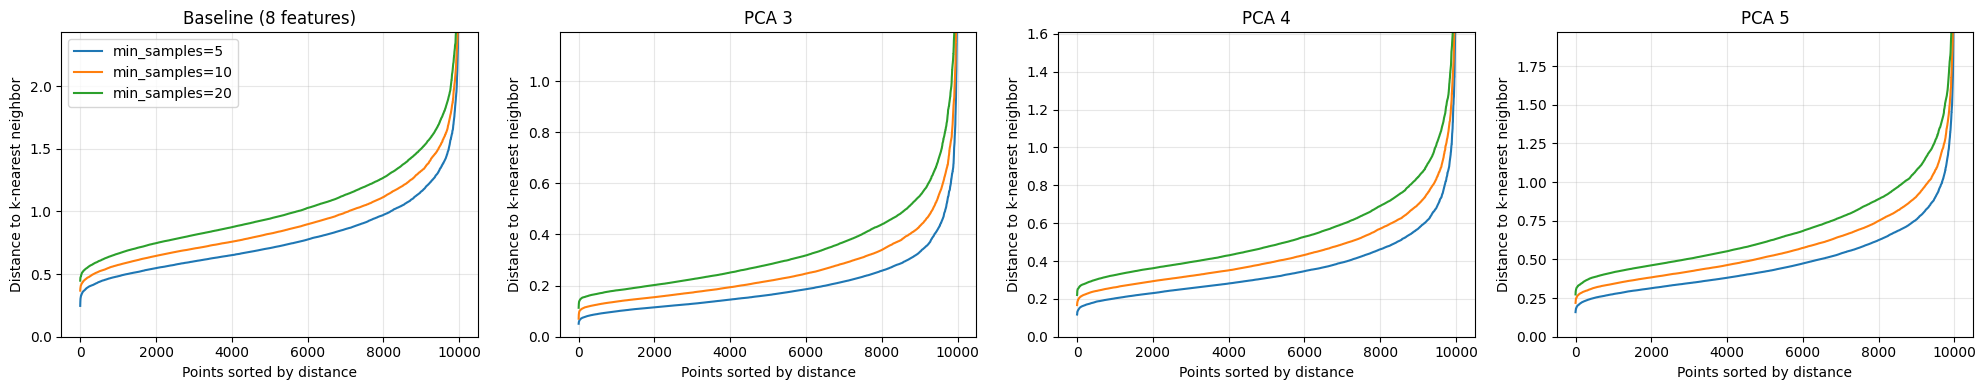

In [32]:
# K-Distance Plot: mostra a distância ao k-ésimo vizinho de cada ponto e ajuda a escolher o eps.
fig, axes = plt.subplots(1, len(espacos_amostra), figsize=(5 * len(espacos_amostra), 4))

for ax, nome in zip(axes, espacos_amostra):
    for ms in MIN_SAMPLES:
        ax.plot(kdists[(nome, ms)], label=f"min_samples={ms}")
    ax.set_ylim(0, np.quantile(np.concatenate([kdists[(nome, ms)] for ms in MIN_SAMPLES]), 0.995))
    ax.set_title(nome)
    ax.set_xlabel("Points sorted by distance")
    ax.set_ylabel("Distance to k-nearest neighbor")
    ax.grid(alpha=0.3)

axes[0].legend()
plt.tight_layout()
plt.show()

## Varredura de Parâmetros (eps x min_samples)

Para cada combinação, treinei o DBSCAN na amostra e registrei número de clusters, ruído, tamanho do maior cluster e silhouette (sem ruído). Esta é a versão ampliada da tabela de silhouette por `eps` que existia antes.

Para reduzir o tempo, o silhouette é calculado em uma amostra fixa de 2 mil pontos não-ruído (`random_state=42`), a mesma nos dois espaços, como no K-Means. O silhouette fica NaN quando a configuração forma só 1 cluster ou quando a amostra sorteada cai em um único cluster (cluster gigante e os demais minúsculos). Por isso os valores podem diferir um pouco de execuções anteriores sem amostragem.

In [33]:
# Tamanho da amostra usada no silhouette (reduz o custo da varredura)
TAMANHO_AMOSTRA_SIL = 2000


def varrer_dbscan(nome):
    """Treina o DBSCAN para cada combinação de min_samples e quantil de eps em um espaço e retorna as métricas de cada uma."""
    # Seleciona as músicas da amostra no espaço do modelo
    Xs = espacos_amostra[nome]
    linhas = []
    for ms in MIN_SAMPLES:
        for q in QUANTIS_EPS:
            # Define o eps pelo quantil da curva de k-distância e treina o DBSCAN
            eps = float(np.quantile(kdists[(nome, ms)], q))
            labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(Xs)

            # Separa os pontos que não são ruído e conta os clusters
            ok = labels != -1
            n_clusters = len(set(labels[ok]))

            # Calcula as métricas de clusters, ruído e tamanho do maior cluster
            linha = {
                "espaco": nome,
                "min_samples": ms,
                "quantil_eps": q,
                "eps": eps,
                "clusters": n_clusters,
                "ruido_pct": (~ok).mean() * 100,
                "maior_cluster_pct": np.bincount(labels[ok]).max() / len(labels) * 100 if n_clusters > 0 else 0.0,
                "silhouette": np.nan,
                "silhouette_8d": np.nan,
            }

            # Calcula o silhouette (sem ruído) só quando há 2 ou mais clusters, em uma amostra fixa (mesmos pontos nos dois espaços)
            if n_clusters >= 2:
                pos_ok = np.where(ok)[0]
                if len(pos_ok) > TAMANHO_AMOSTRA_SIL:
                    pos_ok = np.random.RandomState(42).choice(pos_ok, size=TAMANHO_AMOSTRA_SIL, replace=False)

                # Se o sorteio caiu em um único cluster, o silhouette não existe e fica NaN
                if len(np.unique(labels[pos_ok])) >= 2:
                    linha["silhouette"] = silhouette_score(Xs[pos_ok], labels[pos_ok])
                    linha["silhouette_8d"] = silhouette_score(X_amostra_base[pos_ok], labels[pos_ok])
            linhas.append(linha)
        print(f"{nome} | min_samples={ms} ok")
    return pd.DataFrame(linhas)

In [34]:
# Varre eps x min_samples em cada espaço (baseline e PCA)
res_dbscan = pd.concat([varrer_dbscan(nome) for nome in espacos_amostra], ignore_index=True)

Baseline (8 features) | min_samples=5 ok
Baseline (8 features) | min_samples=10 ok
Baseline (8 features) | min_samples=20 ok
PCA 3 | min_samples=5 ok
PCA 3 | min_samples=10 ok
PCA 3 | min_samples=20 ok
PCA 4 | min_samples=5 ok
PCA 4 | min_samples=10 ok
PCA 4 | min_samples=20 ok
PCA 5 | min_samples=5 ok
PCA 5 | min_samples=10 ok
PCA 5 | min_samples=20 ok


### Resultados - Baseline

In [35]:
# Verifica os resultados da busca de parâmetros no baseline
res_dbscan[res_dbscan["espaco"] == NOME_BASELINE].drop(columns="espaco").round(3)

,min_samples,quantil_eps,eps,clusters,ruido_pct,maior_cluster_pct,silhouette,silhouette_8d
0,5,0.60,0.775,20,27.92,67.97,-0.231,-0.231
1,5,0.70,0.859,17,19.82,75.30,-0.017,-0.017
2,5,0.80,0.972,12,12.35,87.02,-0.101,-0.101
3,5,0.90,1.159,4,4.99,94.81,0.104,0.104
4,5,0.95,1.344,2,2.30,97.63,0.424,0.424
5,5,0.99,1.848,1,0.50,99.50,NaN,NaN
6,10,0.60,0.897,4,23.69,72.76,0.223,0.223
7,10,0.70,0.992,5,16.32,79.32,0.063,0.063
8,10,0.80,1.115,2,9.21,90.74,0.215,0.215
9,10,0.90,1.324,1,3.63,96.37,NaN,NaN


### Resultados - PCA

In [36]:
# Verifica os resultados da busca de parâmetros nos espaços do PCA
res_dbscan[res_dbscan["espaco"] != NOME_BASELINE].round(3)

,espaco,min_samples,quantil_eps,eps,clusters,ruido_pct,maior_cluster_pct,silhouette,silhouette_8d
18,PCA 3,5,0.60,0.186,85,29.56,64.32,-0.422,-0.364
19,PCA 3,5,0.70,0.216,80,21.22,72.27,-0.362,-0.333
20,PCA 3,5,0.80,0.258,55,12.82,79.80,-0.271,-0.253
21,PCA 3,5,0.90,0.331,18,6.08,92.98,-0.277,-0.201
22,PCA 3,5,0.95,0.426,4,3.03,96.67,0.276,0.219
23,PCA 3,5,0.99,0.689,1,0.52,99.48,NaN,NaN
24,PCA 3,10,0.60,0.247,16,28.27,69.65,-0.318,-0.239
25,PCA 3,10,0.70,0.287,16,19.85,76.22,-0.186,-0.177
26,PCA 3,10,0.80,0.340,6,11.59,87.65,-0.051,-0.041
27,PCA 3,10,0.90,0.432,2,5.29,94.63,0.171,0.203


#### Resultados da varredura

Nesta execução (amostra de 10 mil músicas, `random_state=42`, 18 configurações por espaço, 72 no total), 26 configurações têm silhouette positivo, sempre com 2 a 8 clusters e um cluster que concentra de 71% a 98% das músicas. É o caso em que o silhouette engana, porque o resultado é inútil para o recomendador. Por exemplo, o maior silhouette da varredura (0,546, PCA 3 com `min_samples=20` e quantil 0,60) tem 4 clusters, mas 71,5% das músicas num só e 27,8% de ruído. No baseline, `min_samples=20` e quantil 0,70 dão 2 clusters, silhouette 0,423 e 82% das músicas num só.

Outras 28 configurações ficam com silhouette NaN: 27 formam só 1 cluster e 1 (PCA 4, `min_samples=5`, quantil 0,95) teve a amostra do silhouette caindo em um único cluster. Como o silhouette é calculado em uma amostra de 2 mil pontos, os valores podem diferir um pouco de execuções sem amostragem.

## Comparação dos Modelos

Para usar o DBSCAN no recomendador, os clusters precisam ser poucos, interpretáveis e cobrir a maior parte das músicas. Uma configuração só **atende os filtros** se tiver:

- no máximo `MAX_RUIDO_PCT` de ruído;
- pelo menos `MIN_CLUSTERS` clusters;
- nenhum cluster com mais de `MAX_DOMINANTE_PCT` das músicas;
- silhouette acima de `MIN_SILHOUETTE`.

Entre as que atendem, vale a de maior silhouette. Se nenhuma atender, o notebook avisa e usa como **melhor tentativa** a configuração com 3 ou mais clusters e ruído aceitável que tenha o menor cluster dominante. A coluna `atende_filtros` da tabela final mostra qual foi o caso, para a comparação não esconder que um modelo falhou.

### Escolha da Configuração de cada Modelo

In [37]:
# Define os filtros que uma configuração precisa atender
MAX_RUIDO_PCT = 30
MIN_CLUSTERS = 3
MAX_DOMINANTE_PCT = 50
MIN_SILHOUETTE = 0.0


def escolher_config(res_esp):
    """Devolve (configuração, atende_filtros)."""
    nome = res_esp["espaco"].iloc[0]

    # Identifica as configurações com ruído aceitável e clusters suficientes
    base = (res_esp["ruido_pct"] <= MAX_RUIDO_PCT) & (res_esp["clusters"] >= MIN_CLUSTERS)

    # Identifica as configurações que atendem todos os filtros
    valido = base & (res_esp["maior_cluster_pct"] <= MAX_DOMINANTE_PCT) & (res_esp["silhouette"] > MIN_SILHOUETTE)

    # Escolhe a de maior silhouette entre as que atendem os filtros
    if valido.any():
        return res_esp[valido].sort_values("silhouette", ascending=False).iloc[0], True

    # Se nenhuma atender, usa a melhor tentativa (menor cluster dominante)
    print(f"  {nome}: nenhuma configuração atende os filtros; usando a melhor tentativa (menor cluster dominante).")
    if base.any():
        return res_esp[base].sort_values("maior_cluster_pct").iloc[0], False
    return None, False

### Performance Metrics

In [38]:
# Cria os dicionários e a lista que guardam a configuração, os clusters e as métricas de cada modelo
configs, labels_dbscan, linhas = {}, {}, []


# Escolhe a configuração, treina o DBSCAN na amostra e calcula as métricas de cada espaço
for nome in espacos_amostra:
    cfg, atende = escolher_config(res_dbscan[res_dbscan["espaco"] == nome])
    if cfg is None:
        print(f"{nome}: nenhuma configuração formou {MIN_CLUSTERS} ou mais clusters com ruído aceitável.")
        continue

    # Treina o DBSCAN com a configuração escolhida e guarda o cluster de cada música da amostra
    configs[nome] = cfg
    modelo_busca = DBSCAN(eps=cfg["eps"], min_samples=int(cfg["min_samples"]))
    serie = pd.Series(modelo_busca.fit_predict(espacos_amostra[nome]), index=idx_amostra)
    labels_dbscan[nome] = serie

    # Reúne as métricas do modelo em uma linha (métricas de gênero sem o ruído)
    linhas.append({
        "espaco": nome,
        "atende_filtros": atende,
        "eps": cfg["eps"],
        "min_samples": int(cfg["min_samples"]),
        "clusters": cfg["clusters"],
        "ruido_pct": cfg["ruido_pct"],
        "maior_cluster_pct": cfg["maior_cluster_pct"],
        "silhouette": cfg["silhouette"],
        "silhouette_8d": cfg["silhouette_8d"],
        **metricas_genero(serie[serie != -1]),
    })

  Baseline (8 features): nenhuma configuração atende os filtros; usando a melhor tentativa (menor cluster dominante).
  PCA 3: nenhuma configuração atende os filtros; usando a melhor tentativa (menor cluster dominante).
  PCA 4: nenhuma configuração atende os filtros; usando a melhor tentativa (menor cluster dominante).
  PCA 5: nenhuma configuração atende os filtros; usando a melhor tentativa (menor cluster dominante).


In [39]:
# Compara o resultado das métricas de performance para todos os modelos
comparacao_dbscan = pd.DataFrame(linhas)
comparacao_dbscan.round(3)

,espaco,atende_filtros,eps,min_samples,clusters,ruido_pct,maior_cluster_pct,silhouette,silhouette_8d,genero_dominante_pct,entropia_generos
0,Baseline (8 features),False,0.775,5,20,27.92,67.97,-0.231,-0.231,2.423,0.963
1,PCA 3,False,0.186,5,85,29.56,64.32,-0.422,-0.364,3.390,0.939
2,PCA 4,False,0.346,5,56,28.42,66.54,-0.400,-0.319,3.125,0.950
3,PCA 5,False,0.474,5,37,29.39,60.92,-0.306,-0.256,4.003,0.928


#### Resultados da comparação

- **Nenhuma configuração atende os filtros em nenhum espaço**, nem no baseline nem no PCA. Sempre que o DBSCAN forma 3 ou mais clusters com ruído aceitável, o maior cluster tem pelo menos 60,9% de todas as músicas, e quase toda a massa fica num cluster só.
- As melhores tentativas (menor cluster dominante) têm silhouette **negativo**: baseline -0,231, PCA 3 -0,422, PCA 4 -0,400 e PCA 5 -0,306. No baseline são 20 clusters, com 94,3% das músicas não-ruído num deles, e os outros 19 têm 4,4% ou menos.
- **O PCA não ajudou o DBSCAN.** Com 3 a 5 componentes, as melhores tentativas viram dezenas de clusters minúsculos (37 a 85) mais um cluster gigante (86% a 91% das músicas não-ruído), e o silhouette piora em relação ao baseline.
- As métricas de diversidade de gêneros (gênero dominante entre 2,4% e 4,0%, entropia entre 0,93 e 0,96) parecem boas, mas refletem principalmente o cluster gigante, que mistura quase todos os gêneros. Elas não indicam clusters coerentes.

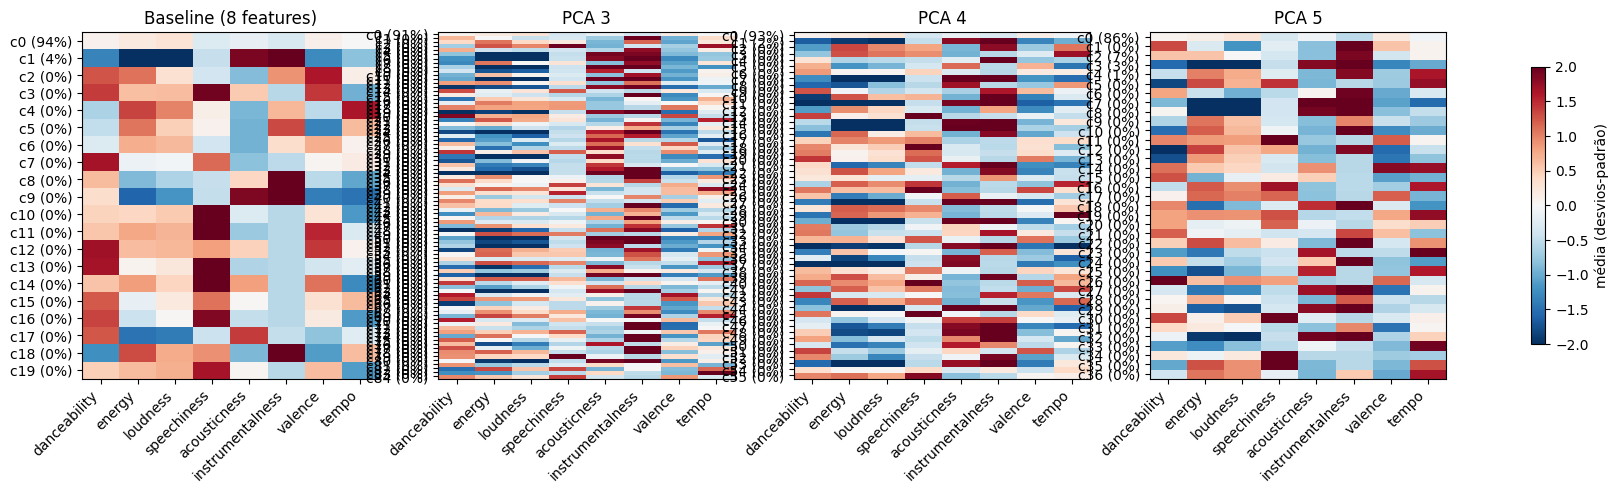


Baseline (8 features)


,pct_musicas,top_generos
cluster,,
0,94.3,"grunge, forro, pop-film"
1,4.4,"new-age, piano, ambient"
2,0.1,"afrobeat, detroit-techno, alt-rock"
3,0.0,"k-pop, salsa, electro"
4,0.1,"happy, heavy-metal, death-metal"
5,0.1,"trance, death-metal, french"
6,0.0,hard-rock
7,0.1,"turkish, anime, dub"
8,0.1,"trip-hop, study, chill"



PCA 3


,pct_musicas,top_generos
cluster,,
0,91.3,"forro, grunge, rock-n-roll"
1,0.2,"minimal-techno, techno, chicago-house"
2,0.1,"detroit-techno, black-metal, club"
3,0.1,"groove, metalcore, hardstyle"
4,0.2,"minimal-techno, techno, idm"
...,...,...
80,0.1,"piano, ambient, british"
81,0.1,"bluegrass, punk-rock, trip-hop"
82,0.1,"death-metal, grindcore, groove"



PCA 4


,pct_musicas,top_generos
cluster,,
0,93.0,"grunge, rock-n-roll, mpb"
1,1.7,"new-age, ambient, classical"
2,0.1,"drum-and-bass, french, grindcore"
3,0.1,"emo, punk, idm"
4,0.1,"trip-hop, french, idm"
5,0.2,"songwriter, singer-songwriter, rock-n-roll"
6,0.1,"pop-film, latino, hip-hop"
7,0.3,"piano, ambient, new-age"
8,0.1,"songwriter, singer-songwriter, acoustic"



PCA 5


,pct_musicas,top_generos
cluster,,
0,86.3,"rock-n-roll, grunge, mpb"
1,0.1,"chicago-house, detroit-techno"
2,7.1,"minimal-techno, techno, detroit-techno"
3,3.4,"new-age, ambient, piano"
4,0.7,"drum-and-bass, happy, trance"
5,0.1,"grunge, hardcore, ska"
6,0.1,"french, minimal-techno, trip-hop"
7,0.1,"classical, piano, ambient"
8,0.1,"guitar, classical, new-age"


In [40]:
fig, axes = plt.subplots(1, len(labels_dbscan), figsize=(5.5 * len(labels_dbscan), 4.5), squeeze=False)
perfis = {}

for ax, (nome, serie) in zip(axes[0], labels_dbscan.items()):
    perfis[nome] = perfil_clusters(serie)
    im = plot_perfil(perfis[nome], nome, ax)

fig.colorbar(im, ax=axes, shrink=0.8, label="média (desvios-padrão)")
plt.show()



# Exibe o percentual de músicas e os gêneros mais comuns de cada cluster
for nome, perfil in perfis.items():
    print(f"\n{nome}")
    display(perfil[["pct_musicas", "top_generos"]].round(1))

#### Resultados do perfil

Nesta execução, no baseline, o cluster 0 concentra 94,3% das músicas não-ruído (grunge, forró, pop-film entre os gêneros mais comuns) e o cluster 1 concentra 4,4% (new-age, piano, ambient). Os outros 18 têm cerca de 0,1% cada. Nos espaços PCA o padrão é parecido: um cluster com 86% a 93% das músicas e dezenas de clusters minúsculos.

### Visualização dos Clusters

Todos os modelos desenhados na mesma projeção PC1 x PC2, com o ruído em cinza.

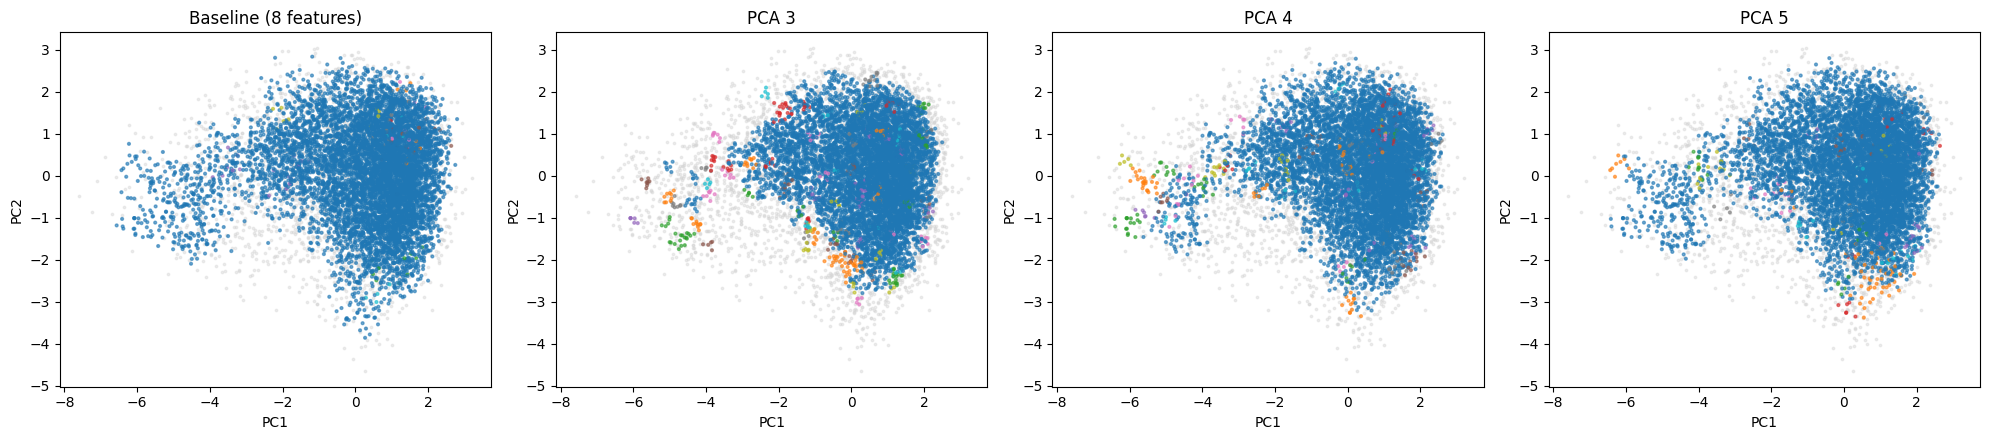

In [41]:
# Projeta as músicas em PC1 x PC2 (mesma projeção para todos os modelos)
pcs_2d = pca_full.transform(X_scaled)[:, :2]


fig, axes = plt.subplots(1, len(labels_dbscan), figsize=(5 * len(labels_dbscan), 4.5), squeeze=False)

for ax, (nome, serie) in zip(axes[0], labels_dbscan.items()):
    plot_pc12(serie.index.to_numpy(), serie.to_numpy(), nome, ax)

plt.tight_layout()
plt.show()

## Conclusão

- Audio features do Spotify formam mais um contínuo do que grupos separados por regiões vazias, e o DBSCAN depende justamente de regiões de densidade separadas. Isso é uma limitação do DBSCAN neste dado, e não um erro de código.
- Os parâmetros foram escolhidos numa amostra de 10 mil músicas. Numa base maior, a mesma `eps` com o mesmo `min_samples` encontra mais vizinhos por ponto e os clusters tendem a se juntar ainda mais, então o cenário completo não deve ser melhor.
- **Conclusão:** o DBSCAN, com ou sem PCA, não produz taste clusters utilizáveis neste dado. Isso é um resultado útil: justifica a escolha do K-Means para o recomendador.

Para manter o pipeline completo e comparável ao do K-Means (Train, Assign, Recommend), as seções seguintes usam o **baseline** com a melhor tentativa da busca. Elas servem para testar o DBSCAN no recomendador, não para substituir o K-Means.

# Train

Treina o DBSCAN final no baseline, com o `eps` e o `min_samples` da melhor tentativa escolhida na seção **Model selection**. O treino usa a mesma amostra de 10 mil músicas da busca de parâmetros, porque o DBSCAN na base inteira é muito mais pesado.

In [42]:
# Recupera a configuração escolhida para o baseline
cfg_final = configs[NOME_BASELINE]
eps_final = float(cfg_final["eps"])
min_samples_final = int(cfg_final["min_samples"])

print(f"eps={eps_final:.3f} | min_samples={min_samples_final}")


# Treina o DBSCAN final na amostra do baseline
model = DBSCAN(eps=eps_final, min_samples=min_samples_final)
model.fit(espacos_amostra[NOME_BASELINE])


print(f"Clusters: {len(set(model.labels_[model.labels_ != -1]))} | Core points: {len(model.core_sample_indices_)}")

eps=0.775 | min_samples=5


Clusters: 20 | Core points: 6000


#### Resultados do treino

Nesta execução, o modelo final usou `eps=0,775` e `min_samples=5`, e formou 20 clusters com 6.000 core points (entre as 10 mil músicas da amostra).

In [43]:
os.makedirs('../artifacts/models/dbscan', exist_ok=True)
joblib.dump(model, "../artifacts/models/kmeans/dbscan_model.joblib")
joblib.dump(scaler, "../artifacts/models/kmeans/dbscan_scaler.joblib")

['../artifacts/models/kmeans/dbscan_scaler.joblib']

# Assign tracks to clusters

O DBSCAN não tem `predict`. A função `dbscan_predict` atribui cada música ao cluster do core point mais próximo, desde que a distância seja menor ou igual a `eps`; caso contrário, a música é ruído (-1). Os pontos da própria amostra mantêm o cluster que o treino atribuiu a eles.

In [44]:
def dbscan_predict(model, X_novo):
    """Atribui cada ponto ao cluster do core point mais próximo, se estiver dentro de eps (senão, ruído = -1)."""
    X_novo = np.asarray(X_novo)

    # Cluster de cada core point do modelo treinado
    core_labels = model.labels_[model.core_sample_indices_]

    # Encontra o core point mais próximo de cada ponto novo
    nn = NearestNeighbors(n_neighbors=1).fit(model.components_)
    dist, pos = nn.kneighbors(X_novo)

    # Herda o cluster do core point mais próximo e marca como ruído o que estiver além de eps
    labels_novo = core_labels[pos[:, 0]]
    labels_novo[dist[:, 0] > model.eps] = -1
    return labels_novo

In [45]:
X = np.asarray(X_scaled)


labels = dbscan_predict(model, X)

print(X.shape)
print(labels.shape)
print(f"Clusters: {len(set(labels[labels != -1]))} | Ruído: {(labels == -1).mean() * 100:.1f}%")

(80175, 8)
(80175,)
Clusters: 20 | Ruído: 29.9%


#### Resultados da atribuição

Nesta execução, a atribuição na base inteira (80.175 músicas) resultou em 20 clusters e 29,9% de ruído, próximo dos 27,9% de ruído da amostra.

# Build input tracks list

In [46]:
genre = "jazz"


input_tracks = df_metadata[df_metadata["genres"].map(lambda g: genre in g)].sample(
    n=input_size,
    random_state=42
)

In [47]:
input_tracks[['track_id', 'artists', 'track_name', 'genres']]

,track_id,artists,track_name,genres
49046,5hyJ1GbE8vZL1BGKE1MSPJ,Tulus,Merdu Untukmu - Outro,[jazz]
12597,5fqDXVrqZRCtyOVFQBONc6,Konteks,Backdrop,"[chill, jazz]"
48275,2etqMd6kibMrZoPCPd2fMi,Robert Broberg,Mitt lilla fejs & jag,"[j-pop, jazz, swedish]"
48056,5iLvprNgPn14wije5V6djv,Robert Broberg,Vatten,"[j-pop, jazz, swedish]"
48333,2MKLbFPQ3QDXpQ0KnS06Kl,Norah Jones,Those Sweet Words,"[j-pop, jazz]"


In [48]:
input_indices = input_tracks.index.to_list()

In [49]:
playlist_id = spo.create_playlist(token)
spo.add_tracks_to_playlist(token, playlist_id, df_metadata.iloc[input_indices]['track_id'])
spo.display_player(playlist_id)

# Recommend

1. Calcula o perfil das músicas de entrada (média das features escaladas)
2. Identifica o cluster do perfil (core point mais próximo dentro de `eps`)
3. Ordena as músicas desse cluster pela distância euclidiana ao perfil, ignorando as músicas de entrada

Como o DBSCAN tem ruído, o perfil pode cair numa região sem core point por perto. Nesse caso, o notebook usa o cluster da música não-ruído mais próxima do perfil e avisa na tela. As recomendações saem sempre de um cluster de verdade: o ruído (-1) nunca entra como candidato.

In [50]:
input_profile = X[input_indices].mean(axis=0).reshape(1, -1)


cluster = dbscan_predict(model, input_profile)[0]

if cluster == -1:
    nao_ruido = np.where(labels != -1)[0]
    mais_proxima = nao_ruido[np.argmin(np.linalg.norm(X[nao_ruido] - input_profile, axis=1))]
    cluster = labels[mais_proxima]
    print(f"O perfil caiu em região de ruído; usando o cluster {cluster}, o da música não-ruído mais próxima.")


candidates = np.where(labels == cluster)[0]
candidates = candidates[~np.isin(candidates, input_indices)]


all_distances = np.linalg.norm(X[candidates] - input_profile, axis=1)
order = np.argsort(all_distances)[:output_size]


distances = all_distances[order].reshape(1, -1)
indices = candidates[order].reshape(1, -1)

O perfil caiu em região de ruído; usando o cluster 0, o da música não-ruído mais próxima.


In [51]:
playlist_id = spo.create_playlist(token)
spo.add_tracks_to_playlist(token, playlist_id, df_metadata.iloc[indices[0]]['track_id'])
spo.display_player(playlist_id)

In [52]:
recommendations = df_metadata.iloc[indices[0]]
recommendations[['track_id', 'artists', 'track_name', 'genres']]

,track_id,artists,track_name,genres
64770,1nLr4BPL8q1w7OgUHk4mSQ,Alberto Vazquez,Encarcelamiento,[rock-n-roll]
75292,2uUlt61KHLLEvJaDn72V6w,Adriana Varela,Anclao en París,[tango]
43618,4RzpaDRpNI2JZQ8LtAC05x,Vismay Patel,Baarish Mein,"[indian, singer-songwriter, songwriter]"
194,6huS9u0BDfeQHq0lObNLPl,Us The Duo,Better Together,[acoustic]
15464,1CfnMFQtuay15XHlNGpCQa,Roger Miller,King Of The Road - Single Version,[country]
28709,0KUu1mcqWylcOhp92A7nSa,Lonely Night;Lost Dreamers,Control Of Me,[french]
66512,4xhWfr0tyA7BGL7eXo8KnV,RØNIN,ALL GIRLS ARE THE SAME,[sad]
65969,41BFw6SQKtl4FOCgaClWHC,Oleg Pogudin,Парижские фантазии,[romance]
66929,7a82xAIszmxuZwxGexgwl2,sorrow;Thomas Reid;Zaini,see you leave,[sad]
60303,5Cr5e4NGjmbcem8nugnf4i,Aditya Rikhari,Kya Karein,[pop]


#### Resultados da recomendação

Nesta execução, o perfil das 5 faixas de jazz caiu em região de ruído (nenhum core point dentro de `eps`), e o fallback usou o cluster 0, que concentra 94,3% das músicas não-ruído. As 10 recomendações vêm desse cluster gigante e têm gêneros variados, sem relação clara com jazz (rock-n-roll, tango, country, french, sad, pop, entre outros). Isso confirma na prática o resultado da seleção: com um cluster dominante, o DBSCAN não separa o gosto musical, e o K-Means é a escolha adequada para o recomendador.